
**1. Daily Logarithmic Return**
\begin{equation*}
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
\end{equation*}

**2. Parkinson Volatility Estimator**

Daily Variance:
\begin{equation*}
\sigma_{\text{Parkinson, daily}}^2 = \frac{\left(\ln\left(\frac{H_t}{L_t}\right)\right)^2}{4 \ln 2}
\end{equation*}

Annualized Volatility:
\begin{equation*}
\sigma_{\text{Parkinson}} = \sqrt{252 \cdot \sigma_{\text{Parkinson, daily}}^2} = \sqrt{252 \cdot \frac{\left(\ln\left(\frac{H_t}{L_t}\right)\right)^2}{4 \ln 2}}
\end{equation*}

**3. Garman-Klass Volatility Estimator**

Daily Variance:
\begin{equation*}
\sigma_{\text{GK, daily}}^2 = \frac{1}{2} \left( \ln\left(\frac{H_t}{L_t}\right) \right)^2 - (2\ln 2 - 1) \left( \ln\left(\frac{C_t}{O_t}\right) \right)^2
\end{equation*}

Annualized Volatility:
\begin{equation*}
\sigma_{\text{GK}} = \sqrt{252 \cdot \max\left(0, \sigma_{\text{GK, daily}}^2\right)}
\end{equation*}

**4. Rolling Realized Volatility**

For a $k$-day rolling window (e.g., $k=5$ or $k=21$):
\begin{equation*}
\sigma_{\text{RV}, k} = \sqrt{252} \cdot \sqrt{\frac{1}{k - 1} \sum_{i=0}^{k-1} \left(r_{t-i} - \bar{r}\right)^2}
\end{equation*}

**5. 5-Day Target Realized Volatility**

Target volatility computed over future period $t+1$ to $t+5$:
\begin{equation*}
\text{Target Vol}_{5\text{d}, t} = \sqrt{252} \cdot \sqrt{\frac{1}{4} \sum_{j=1}^{5} \left(r_{t+j} - \bar{r}_{\text{next 5}}\right)^2}
\end{equation*}



In [1]:

import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.linear_model import Ridge

TICKERS = ["AMC", "BB", "GME"]
START, END = "2018-01-01", "2026-10-21"
TRADING_DAYS = 252
WEEK = 5  # trading days in "next week"


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """df: daily OHLCV for ONE ticker (auto-adjusted for splits/dividends)."""
    out = pd.DataFrame(index=df.index)
    out["close"] = df["Close"]
    out["volume"] = df["Volume"]

    out["log_ret"] = np.log(df["Close"] / df["Close"].shift(1))


    out["parkinson_var"] = (np.log(df["High"] / df["Low"]) ** 2) / (4 * np.log(2))
    out["parkinson_vol"] = np.sqrt(out["parkinson_var"] * TRADING_DAYS)

    gk = 0.5 * np.log(df["High"] / df["Low"]) ** 2 - (2 * np.log(2) - 1) * np.log(df["Close"] / df["Open"]) ** 2
    out["gk_vol"] = np.sqrt(gk.clip(lower=0) * TRADING_DAYS)

    out["rv_5d"] = out["log_ret"].rolling(5).std() * np.sqrt(TRADING_DAYS)
    out["rv_21d"] = out["log_ret"].rolling(21).std() * np.sqrt(TRADING_DAYS)

    out["log_volume"] = np.log1p(df["Volume"])
    out["dollar_volume"] = df["Close"] * df["Volume"]
    out["volume_ma_21"] = df["Volume"].rolling(21).mean()
    out["rel_volume"] = df["Volume"] / out["volume_ma_21"]


    out["target_vol_1d"] = out["parkinson_vol"].shift(-1)
    out["target_vol_5d"] = (
        out["log_ret"].rolling(WEEK).std().shift(-WEEK) * np.sqrt(TRADING_DAYS)
    )
    out["target_logvol_1d"] = out["log_volume"].shift(-1)
    out["target_logvol_5d"] = (
        np.log1p(df["Volume"].rolling(WEEK).mean().shift(-WEEK))
    )
    return out


def main():
    raw = yf.download(
        TICKERS, start=START, end=END, auto_adjust=True,
        group_by="ticker", progress=False,
    )

    frames = []
    for t in TICKERS:
        df = raw[t].dropna(subset=["Close"]).copy()
        feats = build_features(df)
        feats.insert(0, "ticker", t)
        frames.append(feats)

    data = pd.concat(frames).reset_index().rename(columns={"Date": "date"})
    data.to_csv("meme_stock_features.csv", index=False)

    print(data.groupby("ticker")[["rv_21d", "parkinson_vol", "volume"]].describe().T)
    print("\nSaved meme_stock_features.csv", data.shape)


if __name__ == "__main__":
    main()

ticker                        AMC            BB           GME
rv_21d        count  2.191000e+03  2.191000e+03  2.191000e+03
              mean   9.124103e-01  5.552825e-01  8.391093e-01
              std    7.590454e-01  3.073151e-01  7.890173e-01
              min    1.926118e-01  1.986226e-01  1.877898e-01
              25%    4.626819e-01  3.763419e-01  4.442202e-01
              50%    6.998990e-01  4.942091e-01  6.131863e-01
              75%    1.109014e+00  6.268546e-01  9.647026e-01
              max    6.482197e+00  2.759504e+00  6.787690e+00
parkinson_vol count  2.212000e+03  2.212000e+03  2.212000e+03
              mean   7.107357e-01  4.340627e-01  6.429892e-01
              std    5.837269e-01  3.087129e-01  7.120973e-01
              min    1.053448e-01  7.393553e-02  1.016936e-01
              25%    3.745394e-01  2.628312e-01  3.106179e-01
              50%    5.628030e-01  3.612415e-01  4.613206e-01
              75%    8.308700e-01  5.094601e-01  7.246414e-01
        

In [2]:
df = pd.read_csv("meme_stock_features.csv")

print(df.head(20))

          date ticker       close  volume   log_ret  parkinson_var  \
0   2018-01-02    AMC  125.491554  225720       NaN       0.000870   
1   2018-01-03    AMC  122.232010  163100 -0.026318       0.000562   
2   2018-01-04    AMC  117.750175  214100 -0.037356       0.000936   
3   2018-01-05    AMC  114.898064  200900 -0.024520       0.000459   
4   2018-01-08    AMC  112.453445  234740 -0.021506       0.000902   
5   2018-01-09    AMC  113.268333  200480  0.007220       0.000385   
6   2018-01-10    AMC  113.675781  268220  0.003591       0.000915   
7   2018-01-11    AMC  114.898064  214900  0.010695       0.000297   
8   2018-01-12    AMC  117.750175  465680  0.024520       0.000989   
9   2018-01-16    AMC  111.231133  226280 -0.056955       0.001778   
10  2018-01-17    AMC  112.046028  102380  0.007299       0.000159   
11  2018-01-18    AMC  109.193932  196820 -0.025784       0.000396   
12  2018-01-19    AMC  107.564171  131460 -0.015038       0.000251   
13  2018-01-22    AM

In [3]:

df_clean = df.dropna().reset_index(drop=True)

print(f"Original shape: {df.shape}")
print(f"Cleaned shape:  {df_clean.shape}")

Original shape: (6636, 18)
Cleaned shape:  (6558, 18)


# Comparison of Volatility Estimators

| Feature | Inputs Used | Window Horizon | Statistical Efficiency | Best At Capturing | Main Limitation |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Realized Volatility ($rv_{5d}, rv_{21d}$)** | Close prices | Multi-day (5 or 21 days) | Baseline ($1\times$) | Multi-day price trends & overnight gaps | Slow to react; ignores intraday High/Low swings |
| **Parkinson Volatility ($\text{parkinson\_vol}$)** | High, Low prices | Single day (1 day) | $\sim 5\times$ baseline | Intraday range & extreme price spikes | Ignores overnight gaps between close and open |
| **Garman-Klass Volatility ($\text{gk\_vol}$)** | Open, High, Low, Close | Single day (1 day) | $\sim 8\times$ baseline | Intraday range + direction (open-to-close drift) | Still underestimates large overnight gap openings |

---

### Key Theoretical & Practical Differences

#### 1. Information Density (Close-only vs. Intraday Range)
* **Realized Volatility ($rv$):** Only considers the closing price ($P_t$) at market close. It ignores all price action during trading hours.
* **Parkinson and Garman-Klass:** Utilize intraday price extremes ($H_t$ and $L_t$). High and low prices represent the true boundaries of price discovery during the session, capturing significantly more information than a single closing price.

#### 2. Time Horizon: Instantaneous vs. Smoothed
* **Parkinson & Garman-Klass:** Single-day point estimators that answer how volatile the market was during trading hours on day $t$.
* **Realized Volatility ($rv_{5d}, rv_{21d}$):** Rolling window estimates that calculate historical average risk over 1 week or 1 month, creating a lagged response to immediate shocks.

#### 3. Impact on Meme Stocks (GME, AMC, BB)

* **Scenario A: Intraday Short Squeeze**
  * *Event:* Open = \$10, intraday surge to \$50, Close = \$10.50.
  * *Realized Volatility ($rv$):* Captures near-zero volatility due to a negligible close-to-close return (+5%).
  * *Parkinson / Garman-Klass:* Capture a massive volatility spike from the wide High/Low spread ($50/10$).
* **Scenario B: Overnight News/Earnings Gap**
  * *Event:* Day 1 Close = \$10. Day 2 Open = \$30, trades quietly between \$30.00 and \$30.50, Close = \$30.00.
  * *Realized Volatility ($rv$):* Detects a massive volatility spike due to the 200% close-to-close jump.
  * *Parkinson Volatility:* Shows low volatility on Day 2 because the intraday High/Low range ($30.50 / $30.00) was tight, completely missing the overnight gap.

In [4]:
df = pd.read_csv("meme_stock_features.csv", parse_dates=["date"])

WINDOW_START, WINDOW_END = "2020-11-30", "2020-12-09"
bb = df[(df.ticker == "BB") &
        (df.date >= WINDOW_START) & (df.date <= WINDOW_END)].copy()

bb[["date", "close", "volume", "parkinson_vol", "rv_5d", "rv_21d",
    "rel_volume", "target_vol_1d", "target_logvol_1d"]]

,date,close,volume,parkinson_vol,rv_5d,rv_21d,rel_volume,target_vol_1d,target_logvol_1d
2945,2020-11-30,5.87,6862900,0.541285,0.580538,0.466701,1.613925,3.209764,19.612950
2946,2020-12-01,7.00,329454900,3.209764,1.306152,0.718545,16.664008,1.627732,18.827011
2947,2020-12-02,7.45,150129800,1.627732,1.270069,0.726820,5.605397,0.527992,17.512041
2948,2020-12-03,7.46,40307200,0.527992,1.323062,0.728089,1.410822,1.390035,18.061352
2949,2020-12-04,8.52,69814500,1.390035,1.451714,0.817767,2.199143,0.980956,17.613897
2950,2020-12-07,8.25,44629100,0.980956,1.383894,0.843335,1.322431,0.539783,17.107083
2951,2020-12-08,8.52,26885100,0.539783,1.000433,0.835782,0.770521,0.673509,16.792468
2952,2020-12-09,8.31,19628000,0.673509,1.063824,0.854870,0.550777,0.370284,16.206400


In [5]:
df = pd.read_csv("meme_stock_features.csv", parse_dates=["date"])

WINDOW_START, WINDOW_END = "2020-11-30", "2020-12-09"
AMC = df[(df.ticker == "AMC") &
        (df.date >= WINDOW_START) & (df.date <= WINDOW_END)].copy()

AMC[["date", "close", "volume", "parkinson_vol", "rv_5d", "rv_21d",
    "rel_volume", "target_vol_1d", "target_logvol_1d"]]

,date,close,volume,parkinson_vol,rv_5d,rv_21d,rel_volume,target_vol_1d,target_logvol_1d
733,2020-11-30,42.700001,1655500,1.040240,1.604034,1.854646,0.605338,0.761303,14.008616
734,2020-12-01,41.500000,1213010,0.761303,1.493634,1.836146,0.442646,0.897674,13.985052
735,2020-12-02,43.200001,1184760,0.897674,0.496954,1.783627,0.431836,1.783474,15.703805
736,2020-12-03,36.299999,6608090,1.783474,1.266279,1.910239,2.214002,1.244103,15.014189
737,2020-12-04,35.099998,3315730,1.244103,1.236840,1.916197,1.067408,1.106980,14.533541
738,2020-12-07,35.599998,2050390,1.106980,1.314432,1.909848,0.647707,1.025571,14.898353
739,2020-12-08,39.799999,2953060,1.025571,1.689591,1.937101,0.904974,1.371045,14.557029
740,2020-12-09,38.599998,2099120,1.371045,1.635404,1.314514,0.768319,0.799984,14.502278


In [7]:
df = pd.read_csv("meme_stock_features.csv", parse_dates=["date"])

WINDOW_START, WINDOW_END = "2020-11-30", "2020-12-09"
GME = df[(df.ticker == "GME") &
        (df.date >= WINDOW_START) & (df.date <= WINDOW_END)].copy()

GME[["date", "close", "volume", "parkinson_vol", "rv_5d", "rv_21d",
    "rel_volume", "target_vol_1d", "target_logvol_1d"]]

,date,close,volume,parkinson_vol,rv_5d,rv_21d,rel_volume,target_vol_1d,target_logvol_1d
5157,2020-11-30,4.1400,127934000,1.518832,0.726874,0.917307,3.881544,0.943781,17.739770
5158,2020-12-01,3.9500,50615600,0.943781,0.915476,0.822380,1.525926,0.773581,17.266564
5159,2020-12-02,4.1450,31533600,0.773581,0.839266,0.828096,0.936371,0.451692,17.041561
5160,2020-12-03,4.0300,25180000,0.451692,0.871714,0.821147,0.752641,0.585557,17.395992
5161,2020-12-04,4.2250,35890800,0.585557,0.706551,0.781042,1.053803,0.724134,17.201432
5162,2020-12-07,4.0875,29545200,0.724134,0.736743,0.795729,0.854672,0.736819,17.981878
5163,2020-12-08,4.2350,64480800,0.736819,0.651006,0.795807,1.762325,1.023903,18.394661
5164,2020-12-09,3.4150,97431600,1.023903,1.668401,1.123612,2.433443,0.945108,17.224531


## Merge Reddit sentiment with the volatility table

Runs the merge only if the BiLSTM scores file (`bilstm_v2_reddit_scores_reddit.csv`) is available in Colab. If it is not found, the notebook continues price-only, so the plots and the baseline model below still run.

In [10]:
# Reddit sentiment merge. Runs only if the BiLSTM scores file is available; otherwise continues price-only.
import os, glob, numpy as np, pandas as pd

prices = pd.read_csv("meme_stock_features.csv", parse_dates=["date"])

SCORES_NAME = "bilstm_v2_reddit_scores_reddit.csv"
SCORES_PATH = None      # optional: paste the full path of the scores file here
if SCORES_PATH is None:
    candidates = (glob.glob("/content/*bilstm*scores_reddit*.csv")
                  + glob.glob(f"/content/drive/MyDrive/dl-quant_project/DataSource/{SCORES_NAME}")
                  + glob.glob(f"/content/drive/MyDrive/Colab Notebooks/dl-quant_project/DataSource/{SCORES_NAME}"))
    SCORES_PATH = candidates[0] if candidates else None

if SCORES_PATH is None or not os.path.exists(SCORES_PATH):
    print("Reddit scores file not found -> continuing with price-only data (panel = prices).")
    print("To add Reddit sentiment: upload", SCORES_NAME, "to Colab (folder icon, left sidebar) and re-run this cell.")
    panel = prices.copy()
else:
    print("using:", SCORES_PATH)
    S = pd.read_csv(SCORES_PATH, usecols=["ticker", "created_utc", "p_bear", "p_neu", "p_bull"])
    S["dt_et"] = pd.to_datetime(S.created_utc, unit="s", utc=True).dt.tz_convert("America/New_York")

    # after 4pm ET -> counts for the next day
    d = S.dt_et.dt.tz_localize(None)
    S["d"] = d.where(d.dt.hour < 16, d + pd.Timedelta(days=1)).dt.normalize().astype("datetime64[ns]")

    # weekend / holiday -> next trading day of that stock
    cal = (prices[["ticker", "date"]].drop_duplicates().sort_values("date")
           .rename(columns={"date": "trade_date"}))
    cal["trade_date"] = cal["trade_date"].astype("datetime64[ns]")
    S = pd.merge_asof(S.sort_values("d"), cal, left_on="d", right_on="trade_date",
                      by="ticker", direction="forward").dropna(subset=["trade_date"])

    # daily signals
    P = S[["p_bear", "p_neu", "p_bull"]].to_numpy().clip(1e-9, 1)
    S["sent"] = S.p_bull - S.p_bear                       # bullish minus bearish
    S["clar"] = S.sent.abs()                              # how clearly one-sided
    S["amb"] = -(P * np.log(P)).sum(1) / np.log(3)        # 0 = sure, 1 = completely unsure
    daily = (S.groupby(["ticker", "trade_date"])
               .agg(rd_n=("sent", "size"), rd_sent=("sent", "mean"),
                    rd_clar=("clar", "mean"), rd_amb=("amb", "mean"))
               .reset_index().rename(columns={"trade_date": "date"}))
    daily["rd_logn"] = np.log1p(daily.rd_n)

    panel = prices.merge(daily, on=["ticker", "date"], how="left")
    panel["rd_has"] = panel.rd_n.notna().astype(int)
    panel[["rd_n", "rd_logn"]] = panel[["rd_n", "rd_logn"]].fillna(0)
    print(panel.shape, "| ticker-days with Reddit text:", int(panel.rd_has.sum()))
    print(panel.groupby("ticker").rd_has.sum())

panel.to_csv("panel_with_reddit.csv", index=False)


using: /content/bilstm_v2_reddit_scores_reddit.csv
(6636, 24) | ticker-days with Reddit text: 42
ticker
AMC    42
BB      0
GME     0
Name: rd_has, dtype: int64


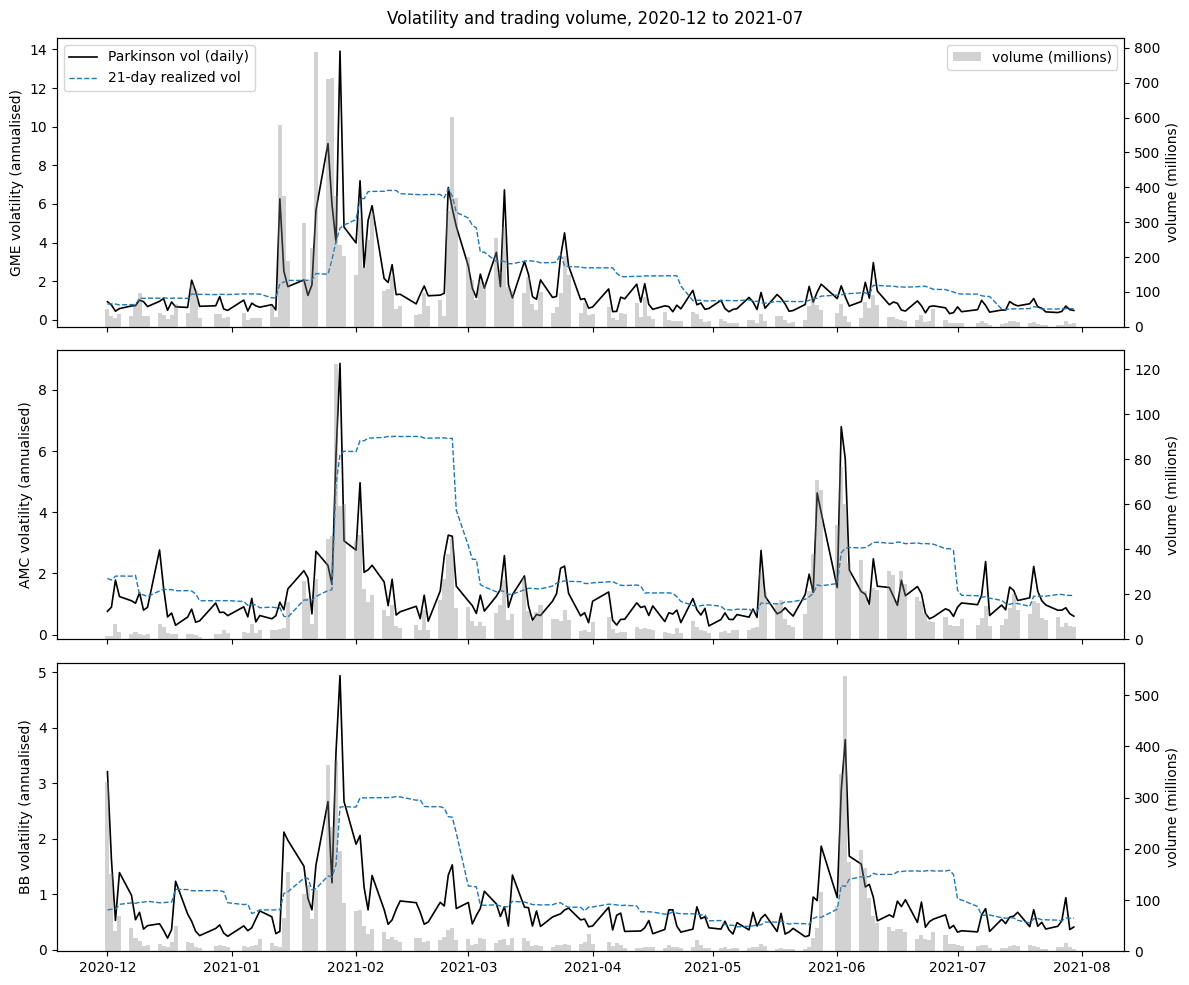

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def plot_reference(panel, start="2020-12-01", end="2021-07-31",
                   tickers=("GME", "AMC", "BB"), out=None):
    # Figure 1: volatility (left axis) and trading volume (right axis), same layout as 04's last plot
    fig, axes = plt.subplots(len(tickers), 1, figsize=(12, 10), sharex=True)
    for ax, t in zip(axes, tickers):
        g = panel[(panel.ticker == t) & (panel.date.between(start, end))]
        ax.plot(g.date, g.parkinson_vol, color="black", lw=1.2, label="Parkinson vol (daily)")
        ax.plot(g.date, g.rv_21d, color="tab:blue", lw=1, ls="--", label="21-day realized vol")
        ax.set_ylabel(t + " volatility (annualised)")
        ax2 = ax.twinx()
        ax2.bar(g.date, g.volume / 1e6, color="tab:grey", alpha=0.35, width=1, label="volume (millions)")
        ax2.set_ylabel("volume (millions)")
        if t == tickers[0]:
            ax.legend(loc="upper left"); ax2.legend(loc="upper right")
    plt.suptitle(f"Volatility and trading volume, {start[:7]} to {end[:7]}")
    plt.tight_layout()
    if out: plt.savefig(out, dpi=120)
    plt.show()

    # Figure 2: volatility vs Reddit QISS (only if the Reddit columns were merged)
    if "rd_sent" in panel.columns and panel.rd_has.sum() > 0:
        panel = panel.sort_values(["ticker", "date"]).copy()
        panel["qiss_reddit"] = np.nan
        for t, g in panel.groupby("ticker"):
            g = g[g.rd_has == 1]
            x = g.rd_sent * (1 - g.rd_amb) * g.rd_logn          # direction x conviction x attention
            mu = x.shift(1).expanding(20).mean(); sd = x.shift(1).expanding(20).std()
            panel.loc[g.index, "qiss_reddit"] = ((x - mu) / sd).clip(-10, 10)
        fig, axes = plt.subplots(len(tickers), 1, figsize=(12, 10), sharex=True)
        for ax, t in zip(axes, tickers):
            g = panel[(panel.ticker == t) & (panel.date.between(start, end))]
            ax.plot(g.date, g.parkinson_vol, color="black", lw=1.2, label="Parkinson vol")
            ax.set_ylabel(t + " volatility")
            ax2 = ax.twinx(); q = g.qiss_reddit.fillna(0)
            ax2.bar(g.date, q, color=np.where(q >= 0, "tab:green", "tab:red"), alpha=0.4, width=1, label="QISS (Reddit)")
            ax2.set_ylabel("QISS (z)"); ax2.axhline(0, color="grey", lw=0.5)
            if t == tickers[0]:
                ax2.legend(loc="upper right"); ax.legend(loc="upper left")
        plt.suptitle("Volatility vs Reddit QISS"); plt.tight_layout(); plt.show()

# run it
try:
    data = panel                                             # from the merge cells, if you have them
except NameError:
    data = pd.read_csv("meme_stock_features.csv", parse_dates=["date"])   # price-only
plot_reference(data)

In [ ]:
df = pd.read_csv("meme_stock_features.csv", parse_dates=["date"])
g = df[df.ticker == "GME"].sort_values("date").copy()
eps = 1e-3
g["f_log_park"] = np.log(g["parkinson_vol"] + eps)           # today's vol
g["f_park_5"]   = g["f_log_park"].rolling(5).mean()          # past week
g["f_park_22"]  = g["f_log_park"].rolling(22).mean()         # past month
g["f_log_volume"] = g["log_volume"]
g["f_rel_volume"] = np.log(g["rel_volume"] + eps)

features = ["f_log_park", "f_park_5", "f_park_22", "f_log_volume", "f_rel_volume"]
g["y"] = np.log(g["target_vol_1d"] + eps)   # tomorrow's volatility
g = g.dropna(subset=features + ["y"])
n = len(g)
train = g.iloc[: int(n * 0.70)]
test  = g.iloc[int(n * 0.70) + 5 :]     # skip 5 days as a gap
mu, sd = train[features].mean(), train[features].std()
Xtr = (train[features] - mu) / sd
Xte = (test[features]  - mu) / sd
model = Ridge(alpha=1.0).fit(Xtr, train["y"])
pred = model.predict(Xte)
def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))

print("HAR_Ridge  :", rmse(test["y"], pred))
print("Persistence:", rmse(test["y"], test["f_log_park"]))        # tomorrow = today
print("TrainMean  :", rmse(test["y"], train["y"].mean()))         # always the average

HAR_Ridge  : 0.42141997614858545
Persistence: 0.5217473560366157
TrainMean  : 0.7522544486517232
